# Classifiez automatiquement des informations - Modélisation

Cellule recap

## 1. Import des modules et du dataset

In [6]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns 
import numpy as np
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

# Validation croisé et finetunning
from sklearn.model_selection import (
    train_test_split,
    GridSearchCV, 
    cross_validate,
    cross_val_predict,
    KFold
)
from sklearn.model_selection import train_test_split

# Import de modèles
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, precision_recall_curve, auc, precision_score, f1_score, classification_report, recall_score

# SMOTE
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import make_pipeline

#SHAP
from shap import TreeExplainer

In [7]:
df = pd.read_csv("../data/processed/dataset_clean.csv")

In [8]:
# On définit notre target
df["a_quitte_l_entreprise_Oui"].describe()
y = df["a_quitte_l_entreprise_Oui"]


# Création de notre df sans target
X = df.drop(columns=["a_quitte_l_entreprise_Oui"])

# Première séparation train test
X_train, X_test, y_train, y_test = train_test_split(
    X,y, test_size=0.10, random_state=42
)
df["a_quitte_l_entreprise_Oui"].value_counts()


a_quitte_l_entreprise_Oui
0.0    1233
1.0     237
Name: count, dtype: int64

## 2. Fonctions

### A. Validation de modèle

Détails de la fonction permettant de tester et d'évaluer les modèles :
1. On entre les caractéristiques de notre validation croisée :
    - On divise le jeu en 5 fold
    - On fixe un random_state pour pouvoir obtenir le même aléatoire pour nos différents tests
2. On définit nos métriques d'évaluation :
    * **F1** :
    * **Rappel** : 
    * **Precision** : 
    * **PR AUC** : 
    * **Time** : la durée d'entrainement de notre modèle
3. On entraine et teste le modèle selon les paramètres définies précédemment
4. On affiche les métriques d'évaluations du modèle


In [9]:
cv_details = KFold(n_splits=5, shuffle=True, random_state=42)
def model_validation(model, X, y, use_smote=False):

    # Metriques chiffrées
    scoring = ["f1", "precision", "recall", "average_precision"]

    steps = []
    if use_smote:
        steps.append(SMOTE(sampling_strategy=0.5, random_state=42))
    steps.append(model)

    pipeline = make_pipeline(*steps)

    cross_validation_result = cross_validate(
        pipeline,
        X, y, 
        cv=cv_details, 
        scoring=scoring, 
        return_train_score=True, 
        return_estimator=True
        )
    
    dict_resultats = {
        "F1": [np.mean(cross_validation_result["train_f1"]), np.mean(cross_validation_result["test_f1"])],
        "Precision": [np.mean(cross_validation_result["train_precision"]), 
                np.mean(cross_validation_result["test_precision"])],
        "Recall": [np.mean(cross_validation_result["train_recall"]), 
                 np.mean(cross_validation_result["test_recall"])],
        "PR AUC" : [np.mean(cross_validation_result["train_average_precision"]), 
                 np.mean(cross_validation_result["test_average_precision"])],
        "Time (sec)": [np.mean(cross_validation_result["fit_time"]), np.mean(cross_validation_result["score_time"])]
    }
    
    df_visuel = pd.DataFrame(dict_resultats, index=["Train (Fit)", "Test (Score)"])
    display(df_visuel)



### B. Matrice de confusion

In [10]:
# Matrice de confusion
def confusion_matrice(model, X, y):    
    y_pred = cross_val_predict(model, X, y, cv=cv_details)
    cm = confusion_matrix(y_train, y_pred)
    display("Matrice de confusion :", cm)

#### C. GridsearchCv / Optimisation de modèle

In [11]:
def optimisation_rfg(X_train, y_train):

    parameters = {
        'n_estimators': [50, 100, 200],           # Nombre d'arbres dans la forêt
        'max_depth': [5, 8, 10, 15, 20, 30],       # Profondeur maximale (clé contre l'overfitting)
        'min_samples_split': [5, 10, 20, 30, 40],           # Min d'échantillons pour diviser un nœud
        'min_samples_leaf': [5, 10, 20, 30, 40, 50],            # Min d'échantillons par feuille (très important)
        'max_features': ['sqrt', 'log2'],     # Diversité des variables par arbre
        'class_weight': ['balanced'] # Gestion du déséquilibre
    }
    clf = RandomForestClassifier()

    rfg = GridSearchCV(clf, parameters, cv = cv_details, scoring = 'recall', verbose = 1)
    rfg.fit(X_train,y_train)
    return rfg

####  D.Graphique de feature Importance

In [12]:
# Prend en entrée un series construit à partir de best_model.feature_importances_
def graph_feature_imp(feature_imp):
    top_10 = feature_imp.head(10)

    plt.figure(figsize=(10, 6))

    top_10.sort_values(ascending=True).plot(
        kind='barh', 
        color='steelblue', 
        edgecolor='black', 
        linewidth=0.5
    )

    plt.title("Les 10 features les plus importantes", fontsize=14, fontweight='bold', pad=15)
    plt.xlabel("Niveau d'importance", fontsize=12)
    plt.ylabel("Caractéristiques", fontsize=12)

    plt.grid(axis='x', linestyle='--', alpha=0.7)

    plt.tight_layout()

    plt.show()

## 3. Test de différents modèles

#### A. Modèle Etalon : Dummy Classifier

In [13]:
# Test du modele Dummy
clf = DummyClassifier()
display("Résultat Dummy Classifier")
model_validation(clf, X_train, y_train)
confusion_matrice(clf, X_train, y_train)

'Résultat Dummy Classifier'

,F1,Precision,Recall,PR AUC,Time (sec)
Train (Fit),0.0,0.0,0.0,0.161754,0.041413
Test (Score),0.0,0.0,0.0,0.161761,0.045867


'Matrice de confusion :'

array([[1109,    0],
       [ 214,    0]])

#### B. Modèle Linéaire : Regression logistique

In [14]:
# Test du modele Regression logistique
clf = LogisticRegression()
display("Résultat Regression logistique")
model_validation(clf, X_train, y_train)
confusion_matrice(clf, X_train, y_train)


# Test du modele de regression logistique avec normalisation
pipeline_logistic_regression = Pipeline([
    ('scaler', StandardScaler()),
    ('logistic_regression', LogisticRegression(class_weight='balanced'))
])
display("Résultat Regression logistique avec normalisation")
model_validation(pipeline_logistic_regression, X_train, y_train)
confusion_matrice(pipeline_logistic_regression, X_train, y_train)

'Résultat Regression logistique'

,F1,Precision,Recall,PR AUC,Time (sec)
Train (Fit),0.245170,0.718908,0.157415,0.495990,0.066551
Test (Score),0.245468,0.695238,0.158575,0.480497,0.019542


'Matrice de confusion :'

array([[1098,   11],
       [ 178,   36]])

'Résultat Regression logistique avec normalisation'

,F1,Precision,Recall,PR AUC,Time (sec)
Train (Fit),0.530626,0.399624,0.789892,0.595681,0.018987
Test (Score),0.491691,0.373558,0.726076,0.557053,0.020253


'Matrice de confusion :'

array([[848, 261],
       [ 59, 155]])

#### C. Modèle non linéaire : Random Forest Classifier

In [15]:
# Test du modele Random Forest Classifier
clf = RandomForestClassifier()
display("Résultat Random Forest Classifier")
model_validation(clf, X_train, y_train)
confusion_matrice(clf, X_train, y_train)

'Résultat Random Forest Classifier'

,F1,Precision,Recall,PR AUC,Time (sec)
Train (Fit),1.000000,1.000000,1.000000,1.000000,0.254088
Test (Score),0.294641,0.846465,0.180515,0.550244,0.048027


'Matrice de confusion :'

array([[1102,    7],
       [ 177,   37]])

### Optimisation d'un modèle

In [16]:
rfg = optimisation_rfg(X_train, y_train)
display(rfg.best_params_)
display(rfg.best_score_)


Fitting 5 folds for each of 1080 candidates, totalling 5400 fits


{'class_weight': 'balanced',
 'max_depth': 15,
 'max_features': 'log2',
 'min_samples_leaf': 50,
 'min_samples_split': 40,
 'n_estimators': 100}

np.float64(0.7414985023534446)

In [17]:
best_model = rfg.best_estimator_
importances = best_model.feature_importances_
feature_imp = pd.Series(
    importances, index=X_train.columns
).sort_values(ascending=False)
display(feature_imp)

heure_supplementaires_Oui                    0.197372
revenu_mensuel                               0.165707
nombre_participation_pee                     0.147881
annees_dans_l_entreprise                     0.119692
tranche_age                                  0.117582
statut_marital_Divorcé(e)                    0.027159
satisfaction_employee_nature_travail         0.027079
satisfaction_employee_environnement          0.023449
distance_domicile_travail                    0.019422
statut_marital_Marié(e)                      0.016527
poste_Cadre Commercial                       0.012861
poste_Consultant                             0.012237
annees_depuis_la_derniere_promotion          0.011822
Diff_evaluation                              0.010576
poste_Représentant Commercial                0.010439
satisfaction_employee_equilibre_pro_perso    0.009962
nombre_experiences_precedentes_4+            0.009932
augmentation_salaire_precedente              0.009476
nb_formations_suivies       

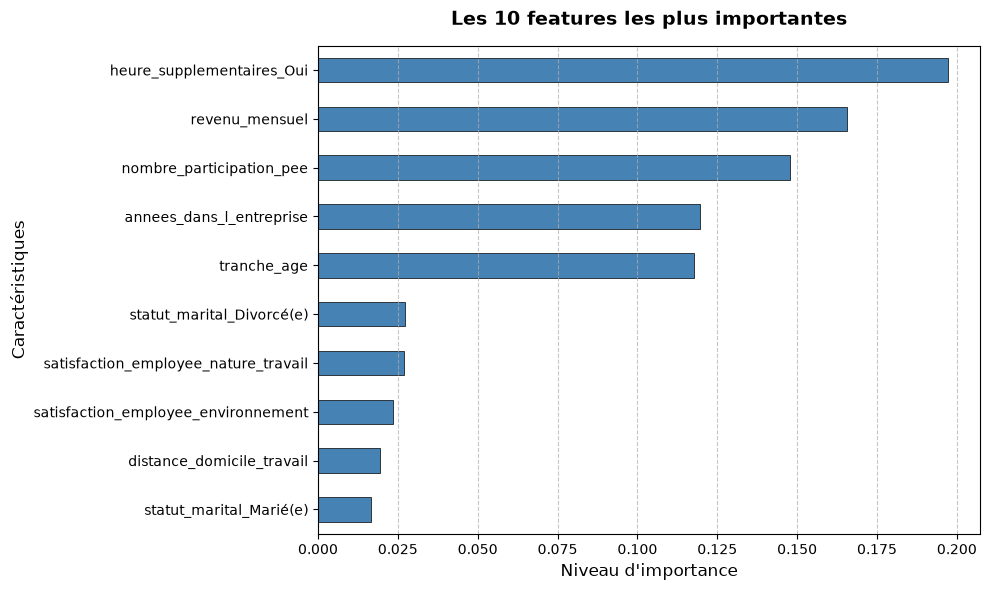

In [18]:
graph_feature_imp(feature_imp)

In [19]:
clf = RandomForestClassifier(
    max_depth= 15,
    max_features= 'sqrt',
    min_samples_split= 20,
    min_samples_leaf=30,
    class_weight= 'balanced',
    n_estimators=50
)


display("Résultat Random Forest Classifier")
model_validation(clf, X_train, y_train, use_smote=True)
confusion_matrice(clf, X_train, y_train)

'Résultat Random Forest Classifier'

,F1,Precision,Recall,PR AUC,Time (sec)
Train (Fit),0.597382,0.581396,0.614592,0.658628,0.142279
Test (Score),0.497219,0.489656,0.507543,0.527413,0.028652


'Matrice de confusion :'

array([[877, 232],
       [ 66, 148]])

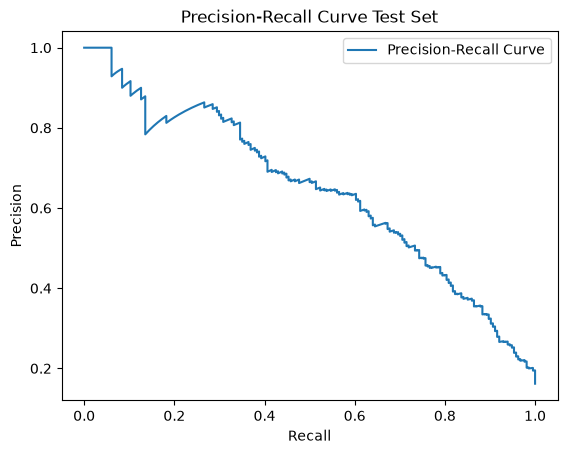

In [20]:
rfg_train = clf.fit(X_train, y_train)
y_proba_test = rfg_train.predict_proba(X_train)[:,1]

precision_test, recall_test, thresholds_test = precision_recall_curve(
    y_train, y_proba_test
)

plt.plot(recall_test, precision_test, label="Precision-Recall Curve")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve Test Set")
plt.legend()
plt.show()


Feature engineering

In [21]:
X["ratio_salaire_anciennete"] = X["revenu_mensuel"] / (X["annees_dans_l_entreprise"] + 1)


X["score_satisfaction_moyen"] = ((X["satisfaction_employee_environnement"] 
                                  + X["satisfaction_employee_nature_travail"] 
                                      + X["satisfaction_employee_equipe"] + X["satisfaction_employee_equilibre_pro_perso"]) / 4)


X["evolution_carriere"] = X["annees_depuis_la_derniere_promotion"] / (X["annees_dans_l_entreprise"] + 1)

X["formation_par_an"] = X["nb_formations_suivies"] / (X["annees_dans_l_entreprise"] +1)
display(X)


X_trainV2, X_testV2, y_trainV2, y_testV2 = train_test_split(
    X,y, test_size=0.10, random_state=42
)


,revenu_mensuel,annees_dans_l_entreprise,nombre_participation_pee,nb_formations_suivies,distance_domicile_travail,niveau_education,annees_depuis_la_derniere_promotion,satisfaction_employee_environnement,satisfaction_employee_nature_travail,satisfaction_employee_equipe,...,domaine_etude_Infra & Cloud,domaine_etude_Marketing,domaine_etude_Transformation Digitale,heure_supplementaires_Oui,nombre_experiences_precedentes_2-3,nombre_experiences_precedentes_4+,ratio_salaire_anciennete,score_satisfaction_moyen,evolution_carriere,formation_par_an
0,5993,6,0,0,1,2,0,2,4,1,...,1.0,0.0,0.0,1.0,0.0,1.0,856.142857,2.00,0.000000,0.000000
1,5130,10,1,3,8,1,1,3,2,4,...,1.0,0.0,0.0,0.0,0.0,0.0,466.363636,3.00,0.090909,0.272727
2,2090,0,0,3,2,2,0,4,3,2,...,0.0,0.0,0.0,1.0,0.0,1.0,2090.000000,3.00,0.000000,3.000000
3,2909,8,0,3,3,4,3,4,3,3,...,1.0,0.0,0.0,1.0,0.0,0.0,323.222222,3.25,0.333333,0.333333
4,3468,2,1,3,2,1,2,1,2,4,...,0.0,0.0,1.0,0.0,0.0,1.0,1156.000000,2.50,0.666667,1.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1465,2571,5,1,3,23,2,0,3,4,3,...,0.0,0.0,1.0,0.0,0.0,1.0,428.500000,3.25,0.000000,0.500000
1466,9991,7,1,5,6,1,1,4,1,1,...,0.0,0.0,1.0,0.0,0.0,1.0,1248.875000,2.25,0.125000,0.625000
1467,6142,6,1,0,4,3,0,2,2,2,...,1.0,0.0,0.0,1.0,0.0,0.0,877.428571,2.25,0.000000,0.000000
1468,5390,9,0,3,2,3,0,4,2,4,...,0.0,0.0,1.0,0.0,1.0,0.0,539.000000,3.00,0.000000,0.300000


In [22]:
rfg = optimisation_rfg(X_trainV2, y_trainV2)
display(rfg.best_params_)
display(rfg.best_score_)

Fitting 5 folds for each of 1080 candidates, totalling 5400 fits


KeyboardInterrupt: 

heure_supplementaires_Oui                    0.203076
nombre_participation_pee                     0.168882
revenu_mensuel                               0.156315
annees_dans_l_entreprise                     0.079898
tranche_age                                  0.060267
formation_par_an                             0.056378
score_satisfaction_moyen                     0.035387
ratio_salaire_anciennete                     0.032255
satisfaction_employee_environnement          0.019592
distance_domicile_travail                    0.018224
evolution_carriere                           0.017884
statut_marital_Marié(e)                      0.016947
satisfaction_employee_nature_travail         0.015553
poste_Cadre Commercial                       0.013673
poste_Consultant                             0.012815
poste_Représentant Commercial                0.012082
nombre_experiences_precedentes_4+            0.008000
annees_depuis_la_derniere_promotion          0.007770
poste_Tech Lead             

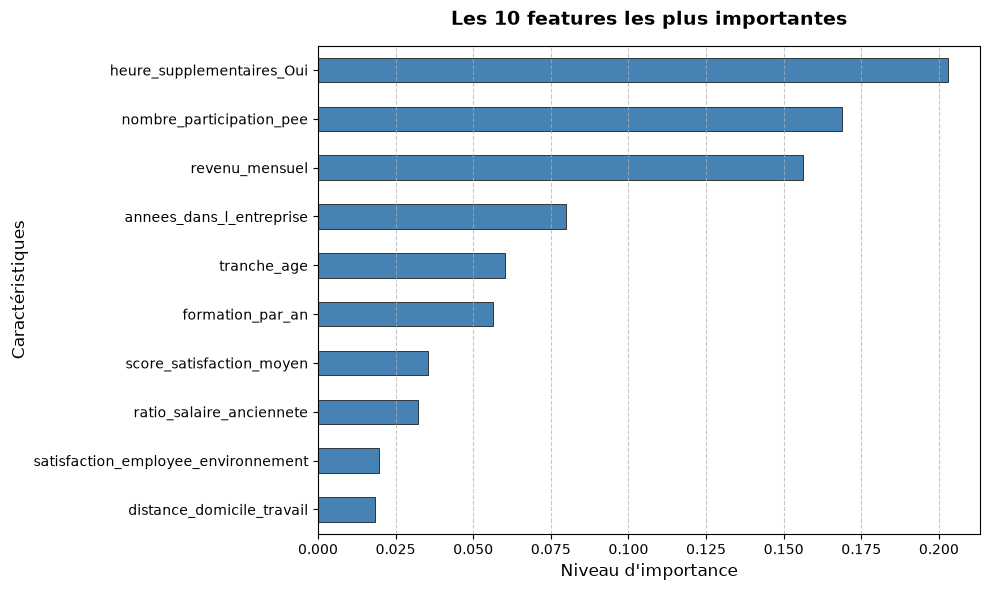

In [ ]:
best_model = rfg.best_estimator_
importances = best_model.feature_importances_
feature_imp = pd.Series(
    importances, index=X_trainV2.columns
).sort_values(ascending=False)
display(feature_imp)

graph_feature_imp(feature_imp)

In [ ]:
clf = RandomForestClassifier(
    max_depth= 5,
    max_features= 'sqrt',
    min_samples_split= 30,
    min_samples_leaf=50,
    class_weight= 'balanced',
    n_estimators=100
)

display("Résultat Random Forest Classifier")
model_validation(clf, X_trainV2, y_trainV2, use_smote=True)
confusion_matrice(clf, X_trainV2, y_trainV2)

'Résultat Random Forest Classifier'

,F1,Precision,Recall,PR AUC,Time (sec)
Train (Fit),0.594390,0.545909,0.653971,0.64341,0.305078
Test (Score),0.520123,0.482954,0.567458,0.55899,0.044980


'Matrice de confusion :'

array([[854, 255],
       [ 64, 150]])

Utilisation de Smote

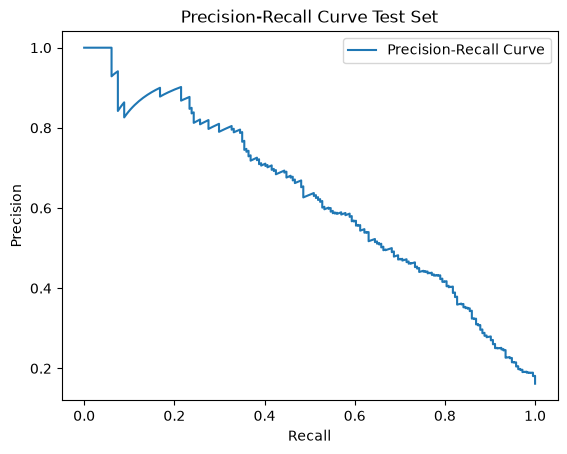

In [ ]:
smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_trainV2, y_trainV2)

rfg_train = clf.fit(X_train_smote, y_train_smote)
y_proba_test = rfg_train.predict_proba(X_trainV2)[:, 1]

precision_test, recall_test, thresholds_test = precision_recall_curve(
    y_trainV2, y_proba_test
)

plt.plot(recall_test, precision_test, label="Precision-Recall Curve")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve Test Set")
plt.legend()
plt.show()

In [ ]:
idx = np.argmin(np.abs(recall_test - 0.8))
print(f"Recall : {recall_test[idx]:.4f}")
print(f"Precision : {precision_test[idx]:.4f}")
if idx < len(thresholds_test):
  print(f"Seuil (Threshold) : {thresholds_test[idx]:.4f}")

Recall : 0.7991
Precision : 0.4161
Seuil (Threshold) : 0.3820


### Interprétation

In [ ]:
explainer = TreeExplainer(rfg_train, approximate=True)
shape_values_train = explainer(X_train)
shap.plots.beeswarm(shap_values_train)

NameError: name 'rfg_train' is not defined